In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

Частина А. Подання зображення

In [2]:
img = cv2.imread('../data/IMG_20261014_194458.jpg')

In [3]:
print('Shape:', img.shape)
print('Dtype:', img.dtype)
print('Min value:', img.min())
print('Max value:', img.max())

Shape: (3280, 2464, 3)
Dtype: uint8
Min value: 0
Max value: 255


(np.float64(-0.5), np.float64(2463.5), np.float64(3279.5), np.float64(-0.5))

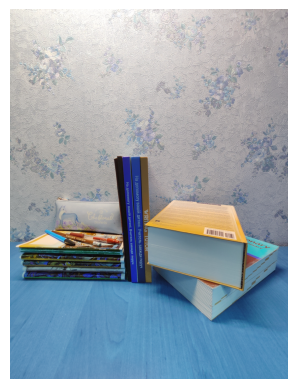

In [4]:
plt.imshow(img)
plt.axis('off')

(np.float64(-0.5), np.float64(2463.5), np.float64(3279.5), np.float64(-0.5))

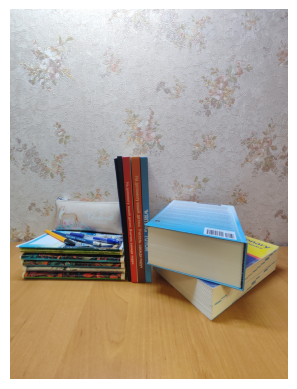

In [5]:
new_img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
plt.imshow(new_img)
plt.axis('off')

In [12]:
bright = new_img + 50
overflow_mask = (new_img > 205) & (bright < 50)
print(f"Количество переполненных значений в каналах: {np.sum(overflow_mask)}")

Количество переполненных значений в каналах: 3766118


(np.float64(-0.5), np.float64(2463.5), np.float64(3279.5), np.float64(-0.5))

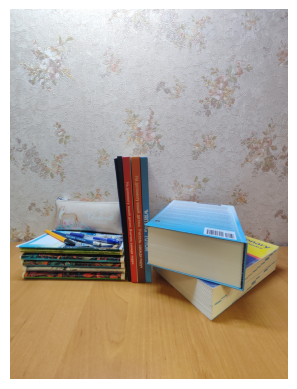

In [13]:
plt.imshow(new_img)
plt.axis('off')

In [ ]:
# cv2.add(new_img, 50)

In [9]:
bright_cv2 = cv2.add(new_img, np.full(new_img.shape, 50, dtype=np.uint8))

(np.float64(-0.5), np.float64(2463.5), np.float64(3279.5), np.float64(-0.5))

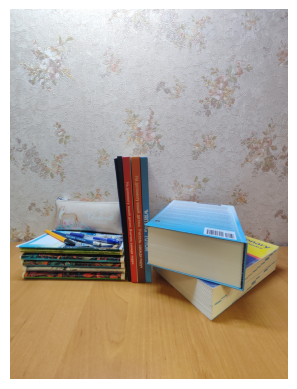

In [10]:
plt.imshow(new_img)
plt.axis('off')

Форма (shape): (3280, 2464, 3)
Тип данных (dtype): uint8
Минимум (min): 0, Максимум (max): 255


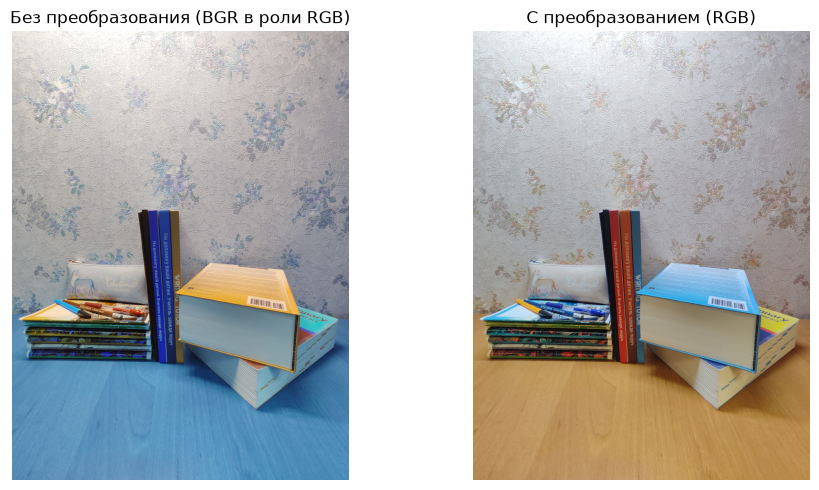

Количество переполненных значений в каналах: 3766118


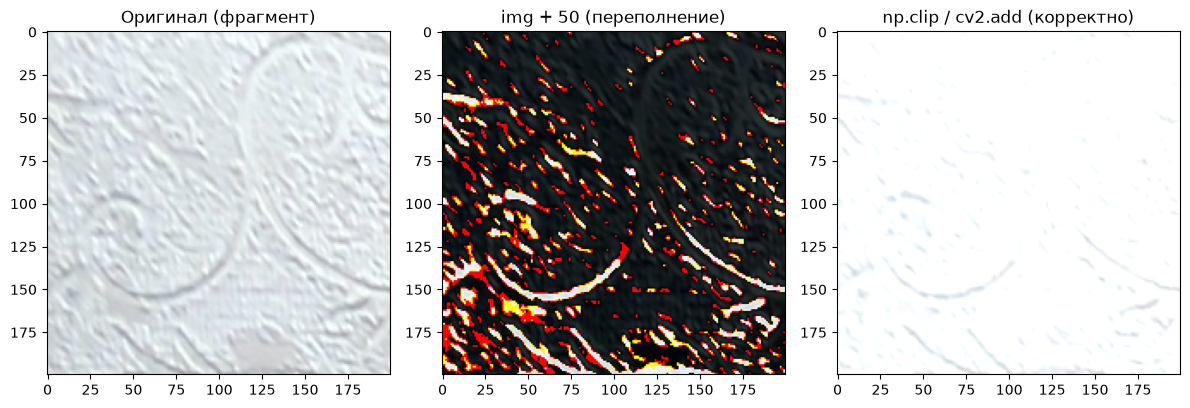

Формат / Качество  Размер файла (КБ)  PSNR (дБ)
 PNG (без потерь)       13983.700195        inf
          JPEG 95        3288.375000  47.265008
          JPEG 75        1316.472656  36.543353
          JPEG 50         907.234375  33.957707
          JPEG 25         612.291992  31.181073
          JPEG 10         348.856445  27.114732


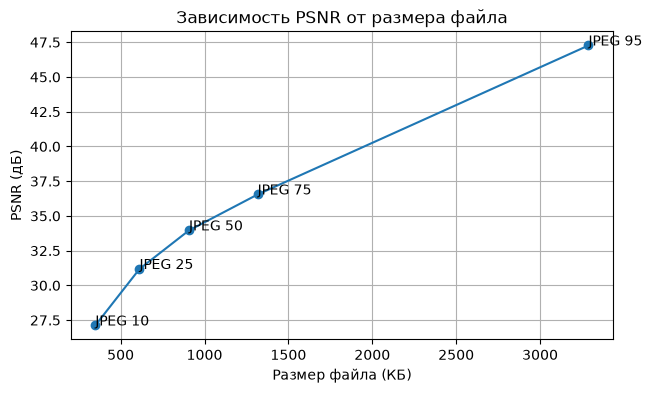

FileNotFoundError: [Errno 2] No such file or directory: 'image.jpg'

In [11]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ExifTags

# ==========================================
# Шаг 1. Чтение изображения и базовые свойства
# ==========================================
img = cv2.imread('../data/IMG_20261014_194458.jpg')  # Замените на путь к вашему фото

print(f"Форма (shape): {img.shape}")
print(f"Тип данных (dtype): {img.dtype}")
print(f"Минимум (min): {img.min()}, Максимум (max): {img.max()}")

# ==========================================
# Шаг 2. Отображение BGR vs RGB
# ==========================================
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title("Без преобразования (BGR в роли RGB)")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img_rgb)
plt.title("С преобразованием (RGB)")
plt.axis('off')
plt.tight_layout()
plt.show()

# ==========================================
# Шаг 3. Переполнение типов (uint8)
# ==========================================
# Некорректное сложение (переполнение по модулю 256)
bright_bad = img_rgb + 50

# Поиск пикселей, которые были яркими (> 205), но стали тёмными (< 50)
overflow_mask = (img_rgb > 205) & (bright_bad < 50)
print(f"Количество переполненных значений в каналах: {np.sum(overflow_mask)}")

# Вариант 1 корректного сложения: через cv2.add (насыщение / saturation)
# Важно: передаём скаляр как массив или добавляем к каждому элементу
bright_cv2 = cv2.add(img_rgb, np.full(img_rgb.shape, 50, dtype=np.uint8))

# Вариант 2 корректного сложения: через int16 и np.clip
bright_clip = np.clip(img_rgb.astype(np.int16) + 50, 0, 255).astype(np.uint8)

# Отображение фрагмента (например, 200x200 пикселей в светлой области)
h, w, _ = img_rgb.shape
crop_y, crop_x = slice(0, min(200, h)), slice(0, min(200, w))

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plt.imshow(img_rgb[crop_y, crop_x])
plt.title("Оригинал (фрагмент)")

plt.subplot(1, 3, 2)
plt.imshow(bright_bad[crop_y, crop_x])
plt.title("img + 50 (переполнение)")

plt.subplot(1, 3, 3)
plt.imshow(bright_clip[crop_y, crop_x])
plt.title("np.clip / cv2.add (корректно)")
plt.tight_layout()
plt.show()

# ==========================================
# Шаг 4. Потери при сжатии и расчёт PSNR
# ==========================================
def calculate_psnr(orig, compressed):
    mse = np.mean((orig.astype(np.float64) - compressed.astype(np.float64)) ** 2)
    if mse == 0:
        return float('inf')
    return 10 * np.log10((255.0 ** 2) / mse)

results = []

# Сохранение в PNG (сжатие без потерь)
png_file = 'compressed.png'
cv2.imwrite(png_file, img)
img_png = cv2.imread(png_file)
results.append({
    'Формат / Качество': 'PNG (без потерь)',
    'Размер файла (КБ)': os.path.getsize(png_file) / 1024,
    'PSNR (дБ)': calculate_psnr(img, img_png)
})

# Сохранение в JPEG с разным качеством
qualities = [95, 75, 50, 25, 10]
for q in qualities:
    jpg_file = f'compressed_q{q}.jpg'
    cv2.imwrite(jpg_file, img, [cv2.IMWRITE_JPEG_QUALITY, q])
    img_jpg = cv2.imread(jpg_file)
    results.append({
        'Формат / Качество': f'JPEG {q}',
        'Размер файла (КБ)': os.path.getsize(jpg_file) / 1024,
        'PSNR (дБ)': calculate_psnr(img, img_jpg)
    })

df_psnr = pd.DataFrame(results)
print(df_psnr.to_string(index=False))

# График зависимости PSNR от размера файла (для JPEG)
jpeg_df = df_psnr[df_psnr['Формат / Качество'] != 'PNG (без потерь)']
plt.figure(figsize=(7, 4))
plt.plot(jpeg_df['Размер файла (КБ)'], jpeg_df['PSNR (дБ)'], marker='o')
for _, row in jpeg_df.iterrows():
    plt.annotate(row['Формат / Качество'], (row['Размер файла (КБ)'], row['PSNR (дБ)']))
plt.xlabel('Размер файла (КБ)')
plt.ylabel('PSNR (дБ)')
plt.title('Зависимость PSNR от размера файла')
plt.grid(True)
plt.show()

# ==========================================
# Шаг 5. Извлечение метаданных EXIF
# ==========================================
pil_img = Image.open('image.jpg')
exif_data = pil_img._getexif()

if exif_data:
    exif = {ExifTags.TAGS.get(k, k): v for k, v in exif_data.items()}
    print("Фокусное расстояние (FocalLength):", exif.get('FocalLength'))
    print("Выдержка (ExposureTime):", exif.get('ExposureTime'))
    print("ISO (ISOSpeedRatings):", exif.get('ISOSpeedRatings'))
else:
    print("EXIF-данные не найдены (используйте оригинал фото с камеры/смартфона без пересылки через мессенджеры).")

Частина В. Колірні простори

In [ ]:
# ==========================================
# Шаги 6–11. Пороговая сегментация в RGB и HSV
# ==========================================
frame1_bgr = cv2.imread('frame1.jpg')
frame2_bgr = cv2.imread('frame2.jpg')

# Читаем эталонные маски в градациях серого и бинаризуем
gt_mask1 = (cv2.imread('mask1.png', cv2.IMREAD_GRAYSCALE) > 127).astype(np.uint8)
gt_mask2 = (cv2.imread('mask2.png', cv2.IMREAD_GRAYSCALE) > 127).astype(np.uint8) # Или gt_mask1, если снимали со штатива

def compute_metrics(pred_mask, gt_mask):
    pred = (pred_mask > 0).astype(np.uint8)
    gt = (gt_mask > 0).astype(np.uint8)
    
    # Доля правильно классифицированных пикселей (Accuracy)
    accuracy = np.mean(pred == gt)
    
    # Intersection over Union (IoU)
    intersection = np.logical_and(pred, gt).sum()
    union = np.logical_or(pred, gt).sum()
    iou = intersection / union if union > 0 else 0.0
    return accuracy, iou

# --- Шаг 8 и 9: Порогование в RGB ---
frame1_rgb = cv2.cvtColor(frame1_bgr, cv2.COLOR_BGR2RGB)
frame2_rgb = cv2.cvtColor(frame2_bgr, cv2.COLOR_BGR2RGB)

# Пример границ в RGB (подберите под цвет вашего объекта на 1-м кадре)
rgb_low = np.array([150, 20, 20], dtype=np.uint8)
rgb_high = np.array([255, 100, 100], dtype=np.uint8)

mask1_rgb = cv2.inRange(frame1_rgb, rgb_low, rgb_high)
mask2_rgb = cv2.inRange(frame2_rgb, rgb_low, rgb_high)

acc1_rgb, iou1_rgb = compute_metrics(mask1_rgb, gt_mask1)
acc2_rgb, iou2_rgb = compute_metrics(mask2_rgb, gt_mask2)

# --- Шаг 10: Порогование в HSV ---
frame1_hsv = cv2.cvtColor(frame1_bgr, cv2.COLOR_BGR2HSV)
frame2_hsv = cv2.cvtColor(frame2_bgr, cv2.COLOR_BGR2HSV)

# Пример границ в HSV (в OpenCV: H in [0, 179], S in [0, 255], V in [0, 255])
# Если объект красный, объедините два диапазона через cv2.bitwise_or: [0..10] и [170..179]
hsv_low = np.array([100, 80, 50], dtype=np.uint8)
hsv_high = np.array([130, 255, 255], dtype=np.uint8)

mask1_hsv = cv2.inRange(frame1_hsv, hsv_low, hsv_high)
mask2_hsv = cv2.inRange(frame2_hsv, hsv_low, hsv_high)

acc1_hsv, iou1_hsv = compute_metrics(mask1_hsv, gt_mask1)
acc2_hsv, iou2_hsv = compute_metrics(mask2_hsv, gt_mask2)

# --- Шаг 11: Сводная таблица ---
summary_df = pd.DataFrame([
    {'Пространство': 'RGB', 'Кадр 1 (Acc)': f"{acc1_rgb:.4f}", 'Кадр 1 (IoU)': f"{iou1_rgb:.4f}", 'Кадр 2 (Acc)': f"{acc2_rgb:.4f}", 'Кадр 2 (IoU)': f"{iou2_rgb:.4f}"},
    {'Пространство': 'HSV', 'Кадр 1 (Acc)': f"{acc1_hsv:.4f}", 'Кадр 1 (IoU)': f"{iou1_hsv:.4f}", 'Кадр 2 (Acc)': f"{acc2_hsv:.4f}", 'Кадр 2 (IoU)': f"{iou2_hsv:.4f}"}
])
print(summary_df.to_string(index=False))

Частина С. Геометрія та радіометрія

In [ ]:
# ==========================================
# Шаг 12. Алиасинг и антиалиасинг (муар)
# ==========================================
tex_img = cv2.cvtColor(cv2.imread('texture.jpg'), cv2.COLOR_BGR2RGB)
h, w, _ = tex_img.shape
new_size = (w // 4, h // 4)

# 1. Прямое уменьшение методом ближайшего соседа
down_nearest = cv2.resize(tex_img, new_size, interpolation=cv2.INTER_NEAREST)

# 2. Предварительное сглаживание фильтром Гаусса + уменьшение
blurred = cv2.GaussianBlur(tex_img, (9, 9), sigmaX=2.0)
down_aa = cv2.resize(blurred, new_size, interpolation=cv2.INTER_NEAREST)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(down_nearest)
plt.title("INTER_NEAREST без сглаживания (виден муар)")
plt.subplot(1, 2, 2)
plt.imshow(down_aa)
plt.title("GaussianBlur + уменьшение (без муара)")
plt.tight_layout()
plt.show()

# ==========================================
# Шаг 13. Сравнение методов интерполяции
# ==========================================
# Вырезаем небольшой фрагмент из оригинала (размеры кратны 8, например 160x160)
patch_hr = tex_img[100:260, 100:260]
ph, pw, _ = patch_hr.shape

# Уменьшаем в 8 раз, чтобы затем восстановить обратно в 8 раз и сравнить с оригиналом по PSNR
patch_lr = cv2.resize(patch_hr, (pw // 8, ph // 8), interpolation=cv2.INTER_AREA)

methods = {
    'INTER_NEAREST': cv2.INTER_NEAREST,
    'INTER_LINEAR': cv2.INTER_LINEAR,
    'INTER_CUBIC': cv2.INTER_CUBIC,
    'INTER_LANCZOS4': cv2.INTER_LANCZOS4
}

plt.figure(figsize=(15, 4))
for idx, (name, flag) in enumerate(methods.items(), 1):
    upscaled = cv2.resize(patch_lr, (pw, ph), interpolation=flag)
    psnr_val = calculate_psnr(patch_hr, upscaled)
    
    plt.subplot(1, 4, idx)
    plt.imshow(upscaled)
    plt.title(f"{name}\nPSNR: {psnr_val:.2f} дБ")
    plt.axis('off')
plt.tight_layout()
plt.show()

# ==========================================
# Шаг 14. Гамма-коррекция
# ==========================================
gammas = [0.5, 1.0, 2.2]
x = np.linspace(0, 1, 256)

plt.figure(figsize=(12, 7))

# Построение передаточных характеристик
plt.subplot(2, 2, 1)
for g in gammas:
    plt.plot(x, x ** g, label=f'γ = {g}')
plt.title("Передаточные характеристики")
plt.xlabel("Входная яркость (нормализованная)")
plt.ylabel("Выходная яркость")
plt.legend()
plt.grid(True)

# Применение гамма-коррекции к изображению
img_norm = img_rgb.astype(np.float32) / 255.0
for idx, g in enumerate(gammas, 2):
    gamma_corrected = np.clip((img_norm ** g) * 255.0, 0, 255).astype(np.uint8)
    plt.subplot(2, 2, idx)
    plt.imshow(gamma_corrected)
    plt.title(f"Гамма γ = {g}")
    plt.axis('off')

plt.tight_layout()
plt.show()